# Post 04 — Does an online corrector earn its place once you wait for the labels?

**Question:** a frozen forecaster makes errors that look learnable. If a small model watches
those errors as they come in and corrects the next forecast, does that beat the frozen
model — once you respect the fact that an *h*-step-ahead forecast's error only exists
*h* steps later?

Two recent papers pull in different directions here:

- **ORCA** (Dai et al., NeurIPS 2026 — [arXiv:2606.14222](https://arxiv.org/abs/2606.14222))
  wraps a frozen, black-box foundation model with an online residual adapter: a linear map
  from the "context of errors" (recent inputs *and* the base forecast) to the base model's
  residual, refit from a recency-weighted replay buffer, with an error-gated "Boltzmann
  router" blending back toward the frozen forecast whenever the adapter has recently been
  worse. It reports ~6% average MSE gains across 5 foundation models and 8 datasets. Its
  released code only trains on labels that have fully matured — checked, not assumed.
- **Training on the Future** (Fentazi, Ameur & Ksentini, 2026 —
  [arXiv:2610.12232](https://arxiv.org/abs/2610.12232)) audits test-time adaptation under
  causal label delay and finds that most published adapters gain little over their frozen
  checkpoints, that "leaky" next-step updates inflate apparent gains by up to 110%, and that
  a closed-form **RLS-Bank** — six recursive-least-squares filters plus a passthrough,
  median-combined, no tunable hyperparameters — sets a bar most adapters fail to clear.

Neither paper tests ORCA against that closed-form bar. This notebook does, in miniature, on
this repo's two series, correcting **Chronos-2's own errors** (something no earlier post
tried — Post 01 Demo 2 corrected ARIMA, Post 03 corrected seasonal-naive):

| Corrector | What it is |
|---|---|
| Frozen Chronos-2 | No correction. The thing every corrector has to beat. |
| ORCA-style ridge adapter | Closed-form ridge on [context window, base forecast path] → residual, refit every *h* released labels. ORCA trains its linear adapter with AdamW; ridge fits the same linear hypothesis class. Not a reproduction. |
| ORCA-style + router | The same adapter behind ORCA's error-gated blend. |
| RLS-Bank | Training on the Future's closed-form corrector, rebuilt from its Appendix D. |
| Residual memory (online) | Post 01 Demo 2's nearest-neighbor retrieval, allowed to retrieve only released residuals. |

**Written down before running anything:** ORCA's own tables give Chronos-2 a **−9.5%** MSE
change on *Electricity* (hourly load — the closest analogue to CISO) and **−0.0%** on
*Exchange* (the closest analogue to SPY's near-random-walk). If those transfer, the
correctors should find something on CISO and nothing on SPY. Post 03's null result (Chronos-2
already captures CISO's daily/weekly shape) is a reason to expect less than that on CISO.

In [1]:
import sys
import warnings

sys.path.insert(0, "../..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import load_electricity, load_spy
from src.evaluation import mae, paired_block_bootstrap, rolling_origin_evaluate, summarize
from src.models import chronos_zero_shot_forecast, naive_forecast, seasonal_naive_forecast
from src.online_correction import (
    BoltzmannRouter,
    OnlineResidualMemory,
    RidgeResidualAdapter,
    RLSBank,
    base_path_forecast,
    build_stream,
    corrected_results,
    run_online,
)
from src.residual_memory import fit_correction_scale

warnings.filterwarnings("ignore")
RESULTS_DIR = "../../results/04-online-residual-correction"

## Scale

`SMALL_SCALE = True` shortens the warm-up / validation / test stretches so the notebook runs
in a few minutes on a laptop CPU, and output files are written without a suffix. Set it to
`False` for the full-scale numbers used in the post (written with a `_fullscale` suffix);
the slow part is Chronos-2 issuing a forecast at **every** time step — about 6,000 calls for
CISO and 1,500 for SPY, at roughly 0.1 s each on CPU.

Unlike earlier posts, origins here are stride 1, not spaced out: an online corrector learns
from a *stream* of forecasts, so every step's forecast exists whether or not it's scored.

In [2]:
SMALL_SCALE = True

if SMALL_SCALE:
    CISO_HISTORY = 8_000
    CISO_WARMUP, CISO_VAL, CISO_TEST = 200, 200, 200
    SPY_WARMUP, SPY_VAL, SPY_TEST = 100, 100, 100
else:
    CISO_HISTORY = None
    CISO_WARMUP, CISO_VAL, CISO_TEST = 2_000, 2_000, 2_000
    SPY_WARMUP, SPY_VAL, SPY_TEST = 500, 500, 500

SUFFIX = "" if SMALL_SCALE else "_fullscale"
CHRONOS_MAX_CONTEXT = 512

ciso = load_electricity("CISO")
if CISO_HISTORY:
    ciso = ciso.iloc[-CISO_HISTORY:]
spy = load_spy()

SERIES = {
    "CISO": dict(
        series=ciso, horizons={"short": 6, "medium": 24, "long": 168},
        warmup=CISO_WARMUP, val=CISO_VAL, test=CISO_TEST,
        baseline=("Seasonal naive", seasonal_naive_forecast, {"season_length": 24}),
        context_length=168,        # one week of hourly context for the ridge adapter
        season_length=24, level_window=24,   # RLS-Bank features (daily cycle)
        memory_lookback=48,        # Post 01 Demo 2 / Post 03 setting
        half_lives=[None, 1_000],
        block_length=48,           # bootstrap blocks: 2x the daily period
    ),
    "SPY": dict(
        series=spy, horizons={"short": 1, "medium": 5, "long": 20},
        warmup=SPY_WARMUP, val=SPY_VAL, test=SPY_TEST,
        baseline=("Naive", naive_forecast, {}),
        context_length=20,         # about a trading month
        season_length=1, level_window=5,
        memory_lookback=20,
        half_lives=[None, 250],
        block_length=10,           # two trading weeks
    ),
}

# Widened from [1, 10, 100, 1000] after the first SMALL_SCALE smoke run, where validation
# picked both ends of that grid -- a sign the grid didn't bracket the optimum.
RIDGE_ALPHAS = [0.1, 1.0, 10.0, 100.0, 1_000.0, 10_000.0]
ROUTER_TAUS = [0.03, 0.1, 0.3, 1.0]
MEMORY_SCALE_GRID = np.linspace(0.0, 1.5, 7)

## One base stream per series

Chronos-2 runs once per series over warm-up + validation + test, at every step, through the
shared `rolling_origin_evaluate` harness (`base_path_forecast` just keeps the full forecast
path, which the ORCA-style adapter conditions on). Every corrector then *replays* this same
cached stream — so differences between correctors come from the update rule alone, never
from re-running the base model.

The three stretches:

- **Warm-up** — correctors are already learning online, but nothing is scored. An online
  corrector deployed for real would have some history behind it, too.
- **Validation** — every hyperparameter choice (ridge strength, buffer half-life, router
  temperature, residual-memory scale) is made here, per horizon.
- **Test** — scored once, from the *same continuous run*: the chosen corrector just keeps
  going. No refitting on test, no retuning.

In [3]:
def run_base(cfg):
    series = cfg["series"]
    horizons = sorted(cfg["horizons"].values())
    n_origins = cfg["warmup"] + cfg["val"] + cfg["test"]
    first_origin = len(series) - max(horizons) + 1 - n_origins

    base = rolling_origin_evaluate(
        series, base_path_forecast, "Chronos-2 (frozen)", horizons, first_origin, step=1,
        model_kwargs={"base_fn": chronos_zero_shot_forecast,
                      "base_kwargs": {"max_context_length": CHRONOS_MAX_CONTEXT}},
    )
    name, fn, kwargs = cfg["baseline"]
    baseline = rolling_origin_evaluate(series, fn, name, horizons, first_origin, step=1, model_kwargs=kwargs)

    stream = build_stream(series, base, cfg["context_length"])
    phase = np.array(["warmup"] * cfg["warmup"] + ["val"] * cfg["val"] + ["test"] * cfg["test"])
    origin_phase = dict(zip(stream.origins, phase))
    print(f"{len(stream.origins)} origins: test {stream.origins[-cfg['test']]} -> {stream.origins[-1]}")
    return base, baseline, stream, origin_phase


bases = {name: run_base(cfg) for name, cfg in SERIES.items()}

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

600 origins: test 2026-08-02 17:00:00+00:00 -> 2026-08-11 00:00:00+00:00


300 origins: test 2026-02-25 00:00:00 -> 2026-07-20 00:00:00


## Validation-only selection

Each corrector is run online over the whole stream; validation MAE (per horizon) picks its
settings; the chosen run's test rows are what get reported. The RLS-Bank has no settings to
choose — that's part of Training on the Future's point.

Released labels follow the **minimum causal delay** here: the *h*-step label of origin *j*
reaches the corrector at step *j + h*, the moment it has actually been observed. The delay
axis comes after.

In [4]:
def val_mae(results, origin_phase, horizon):
    rows = results[(results["horizon"] == horizon) & (results["origin"].map(origin_phase) == "val")]
    return mae(rows["actual"], rows["forecast"])


def select_per_horizon(runs, origin_phase, horizons):
    # runs: {config_key: results frame}. Returns {horizon: best config_key} by validation MAE.
    return {h: min(runs, key=lambda key: val_mae(runs[key], origin_phase, h)) for h in horizons}


def stitch(runs, choice, model_name):
    # Each horizon's rows come from the run validation picked for that horizon.
    parts = [runs[key][runs[key]["horizon"] == h] for h, key in choice.items()]
    return pd.concat(parts, ignore_index=True).assign(model=model_name)


def run_corrector(base, stream, make, name, delay=1.0):
    forecasts, elapsed = run_online(stream, make, delay=delay)
    return corrected_results(base, stream, forecasts, elapsed, name)


def fit_all(name, cfg, base, stream, origin_phase):
    horizons = stream.horizons
    out, chosen = {}, {}

    # ORCA-style ridge adapter: grid over ridge strength x buffer half-life.
    ridge_runs = {}
    for alpha in RIDGE_ALPHAS:
        for half_life in cfg["half_lives"]:
            make = lambda s, k, a=alpha, hl=half_life: RidgeResidualAdapter(s, k, ridge_alpha=a, half_life=hl)
            ridge_runs[(alpha, half_life)] = run_corrector(base, stream, make, "tmp")
    ridge_choice = select_per_horizon(ridge_runs, origin_phase, horizons)
    out["ORCA-style ridge"] = stitch(ridge_runs, ridge_choice, "ORCA-style ridge")
    chosen["ORCA-style ridge"] = ridge_choice

    def make_ridge(s, k):
        alpha, half_life = ridge_choice[s.horizons[k]]
        return RidgeResidualAdapter(s, k, ridge_alpha=alpha, half_life=half_life)

    # Router on top of the already-chosen adapter: pick the temperature on validation too.
    router_runs = {
        tau: run_corrector(base, stream, lambda s, k, t=tau: BoltzmannRouter(make_ridge(s, k), tau=t), "tmp")
        for tau in ROUTER_TAUS
    }
    router_choice = select_per_horizon(router_runs, origin_phase, horizons)
    out["ORCA-style ridge + router"] = stitch(router_runs, router_choice, "ORCA-style ridge + router")
    chosen["ORCA-style ridge + router"] = router_choice

    # RLS-Bank: nothing to tune.
    make_rls = lambda s, k: RLSBank(s, k, season_length=cfg["season_length"], level_window=cfg["level_window"])
    out["RLS-Bank"] = run_corrector(base, stream, make_rls, "RLS-Bank")

    # Residual memory: run once at full strength, then choose the scale on validation --
    # the correction is linear in the scale, so no rerun is needed (same as Post 01).
    memory_full = run_corrector(
        base, stream, lambda s, k: OnlineResidualMemory(s, k, lookback=cfg["memory_lookback"]), "tmp",
    )
    correction = memory_full["forecast"].to_numpy() - base.sort_values(["train_size", "horizon"])["forecast"].to_numpy()
    memory_full = memory_full.assign(correction=correction)
    scales = {}
    for h in horizons:
        rows = memory_full[(memory_full["horizon"] == h) & (memory_full["origin"].map(origin_phase) == "val")]
        scales[h] = fit_correction_scale(rows["actual"], rows["forecast"] - rows["correction"],
                                         rows["correction"], grid=MEMORY_SCALE_GRID)
    memory = memory_full.copy()
    memory["forecast"] = memory["forecast"] - memory["correction"] + memory["horizon"].map(scales) * memory["correction"]
    memory["scaled_absolute_error"] = (memory["actual"] - memory["forecast"]).abs() / memory["mase_scale"]
    memory["direction_correct"] = (
        np.sign(memory["actual"] - memory["origin_actual"]) == np.sign(memory["forecast"] - memory["origin_actual"])
    )
    out["Residual memory (online)"] = memory.drop(columns=["correction"]).assign(model="Residual memory (online)")
    chosen["Residual memory (online)"] = scales

    factories = {"ORCA-style ridge": make_ridge,
                 "ORCA-style ridge + router":
                     lambda s, k: BoltzmannRouter(make_ridge(s, k), tau=router_choice[s.horizons[k]]),
                 "RLS-Bank": make_rls}
    return out, chosen, factories


fitted = {}
for name, cfg in SERIES.items():
    base, baseline, stream, origin_phase = bases[name]
    fitted[name] = fit_all(name, cfg, base, stream, origin_phase)
    print(f"\n{name} -- validation-selected settings per horizon:")
    for model, choice in fitted[name][1].items():
        print(f"  {model}: {choice}")


CISO -- validation-selected settings per horizon:
  ORCA-style ridge: {6: (1000.0, 1000), 24: (10000.0, 1000), 168: (0.1, None)}
  ORCA-style ridge + router: {6: 1.0, 24: 0.03, 168: 0.03}
  Residual memory (online): {6: 0.75, 24: 0.0, 168: 0.0}



SPY -- validation-selected settings per horizon:
  ORCA-style ridge: {1: (1.0, 250), 5: (1.0, 250), 20: (10000.0, 250)}
  ORCA-style ridge + router: {1: 0.03, 5: 1.0, 20: 0.03}
  Residual memory (online): {1: 0.5, 5: 0.25, 20: 0.0}


## Results on the test stretch

MASE here is scaled by the in-sample one-step naive error, as in Post 03, so compare
models *within* a horizon. `mean_elapsed_seconds` is per origin and includes Chronos-2's
own cost — a corrector never runs without the base model underneath it.

In [5]:
def test_rows(results, origin_phase):
    return results[results["origin"].map(origin_phase) == "test"]


all_test, summaries = {}, []
for name, cfg in SERIES.items():
    base, baseline, stream, origin_phase = bases[name]
    frames = [base.drop(columns=["base_path"]), baseline] + list(fitted[name][0].values())
    test = pd.concat([test_rows(f, origin_phase) for f in frames], ignore_index=True)
    all_test[name] = test
    summary = summarize(test)
    summary.insert(0, "series", name)
    summary["horizon_label"] = summary["horizon"].map({v: k for k, v in cfg["horizons"].items()})
    summaries.append(summary)

summary = pd.concat(summaries, ignore_index=True)[
    ["series", "model", "horizon", "horizon_label", "n_forecasts", "mae", "rmse", "mase",
     "directional_accuracy", "mean_elapsed_seconds"]
]
summary.to_csv(f"{RESULTS_DIR}/metrics/online_correction_summary{SUFFIX}.csv", index=False)
pd.concat(all_test.values(), ignore_index=True).drop(columns=["base_path"], errors="ignore").to_csv(
    f"{RESULTS_DIR}/metrics/online_correction_test_forecasts{SUFFIX}.csv", index=False)
summary

,series,model,horizon,horizon_label,n_forecasts,mae,rmse,mase,directional_accuracy,mean_elapsed_seconds
0,CISO,Chronos-2 (frozen),6,short,200,635.487529,879.168758,0.753065,0.995,0.103505
1,CISO,Chronos-2 (frozen),24,medium,200,781.564287,1033.886387,0.925789,0.730,0.103505
2,CISO,Chronos-2 (frozen),168,long,200,2301.417012,2909.536378,2.720932,0.660,0.103505
3,CISO,ORCA-style ridge,6,short,200,609.402604,850.637194,0.722261,0.995,0.104396
4,CISO,ORCA-style ridge,24,medium,200,735.511049,1005.082564,0.871356,0.825,0.104340
5,CISO,ORCA-style ridge,168,long,200,3101.148445,4570.989515,3.664875,0.495,0.104455
6,CISO,ORCA-style ridge + router,6,short,200,607.557811,848.346456,0.720028,0.995,0.104348
7,CISO,ORCA-style ridge + router,24,medium,200,755.970804,1020.928362,0.895536,0.765,0.105116
8,CISO,ORCA-style ridge + router,168,long,200,2548.307220,3608.242683,3.012539,0.525,0.105116
9,CISO,RLS-Bank,6,short,200,681.383585,940.565404,0.807625,0.995,0.103981


### Is any gap real?

Overlapping multi-step forecasts make neighboring origins' errors strongly correlated, so a
plain "% better" can look much more certain than it is. Following Training on the Future,
each corrector is compared with frozen Chronos-2 on paired per-origin errors, with a
circular moving-block bootstrap (blocks of twice the seasonal period). Negative = the
corrector had lower error; "significant" = the 95% interval excludes zero.

In [6]:
FROZEN = "Chronos-2 (frozen)"
rows = []
for name, cfg in SERIES.items():
    test = all_test[name]
    for model in test["model"].unique():
        if model == FROZEN:
            continue
        for h in sorted(cfg["horizons"].values()):
            a = test[(test["model"] == model) & (test["horizon"] == h)].sort_values("origin")
            b = test[(test["model"] == FROZEN) & (test["horizon"] == h)].sort_values("origin")
            result = paired_block_bootstrap(a["scaled_absolute_error"], b["scaled_absolute_error"],
                                            block_length=cfg["block_length"])
            rows.append({"series": name, "model": model, "horizon": h,
                         "pct_change_vs_frozen": 100 * result["mean_diff"] / b["scaled_absolute_error"].mean(),
                         **result})

significance = pd.DataFrame(rows)
significance.to_csv(f"{RESULTS_DIR}/metrics/online_correction_vs_frozen{SUFFIX}.csv", index=False)
significance.round(4)

,series,model,horizon,pct_change_vs_frozen,mean_diff,ci_low,ci_high,significant
0,CISO,Seasonal naive,6,105.7683,0.7965,0.3927,1.2038,True
1,CISO,Seasonal naive,24,73.5692,0.6811,0.3063,1.1027,True
2,CISO,Seasonal naive,168,0.0628,0.0017,-0.3991,0.2772,False
3,CISO,ORCA-style ridge,6,-4.0905,-0.0308,-0.1293,0.0627,False
4,CISO,ORCA-style ridge,24,-5.8796,-0.0544,-0.1130,0.0074,False
5,CISO,ORCA-style ridge,168,34.6919,0.9439,0.1959,1.7173,True
6,CISO,ORCA-style ridge + router,6,-4.3870,-0.0330,-0.0810,0.0143,False
7,CISO,ORCA-style ridge + router,24,-3.2678,-0.0303,-0.0651,0.0061,False
8,CISO,ORCA-style ridge + router,168,10.7172,0.2916,0.0105,0.6036,True
9,CISO,RLS-Bank,6,7.2451,0.0546,-0.0208,0.1290,False


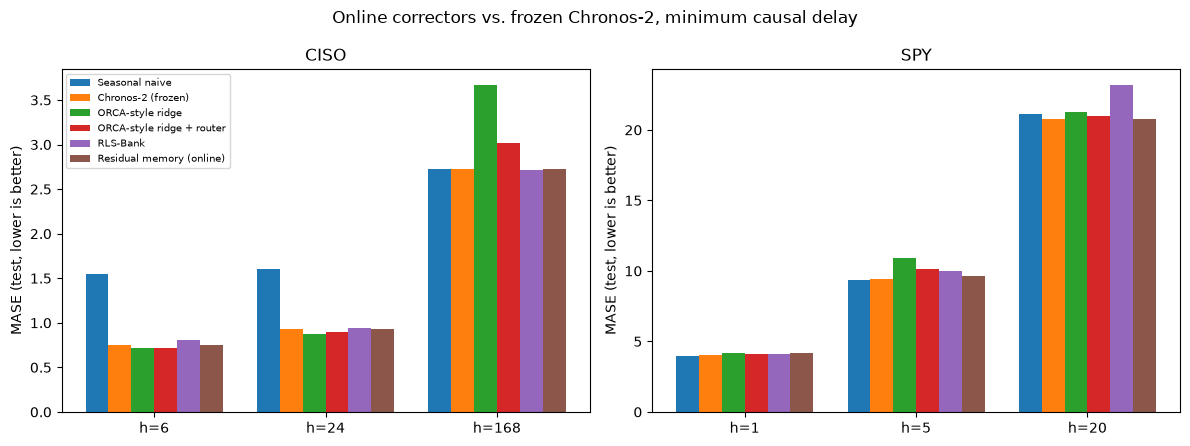

In [7]:
models_order = [FROZEN, "ORCA-style ridge", "ORCA-style ridge + router", "RLS-Bank", "Residual memory (online)"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, cfg) in zip(axes, SERIES.items()):
    s = summary[summary["series"] == name]
    horizons = sorted(cfg["horizons"].values())
    width = 0.8 / (len(models_order) + 1)
    baseline_name = cfg["baseline"][0]
    for i, model in enumerate([baseline_name] + models_order):
        vals = [s[(s["model"] == model) & (s["horizon"] == h)]["mase"].iloc[0] for h in horizons]
        ax.bar(np.arange(len(horizons)) + i * width, vals, width, label=model)
    ax.set_xticks(np.arange(len(horizons)) + 0.4 - width / 2)
    ax.set_xticklabels([f"h={h}" for h in horizons])
    ax.set_title(name)
    ax.set_ylabel("MASE (test, lower is better)")
axes[0].legend(fontsize=7)
fig.suptitle("Online correctors vs. frozen Chronos-2, minimum causal delay")
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/figures/mase_by_horizon{SUFFIX}.png", dpi=150)
plt.show()

## The delay axis: what does waiting for labels cost — and what does *not* waiting buy?

The chosen settings are frozen (no re-selection) and each corrector is replayed three ways:

- **leaky** — every label handed over one step after the forecast, *before* an *h* > 1 target
  exists. This is the legacy protocol Training on the Future audits. It's here only to show
  how much it flatters a corrector; it is not a usable result.
- **1× h** — the minimum causal delay (the setting used above).
- **2× h** — an extra *h* steps of pipeline latency, as if data arrived late.

Residual memory is left out of this sweep (its validation-chosen scale was fit on the 1× run).

In [8]:
DELAYS = ["leaky", 1.0, 2.0]
delay_rows = []
for name, cfg in SERIES.items():
    base, baseline, stream, origin_phase = bases[name]
    frozen_test = test_rows(base, origin_phase)
    for model, make in fitted[name][2].items():
        for delay in DELAYS:
            results = fitted[name][0][model] if delay == 1.0 else run_corrector(base, stream, make, model, delay=delay)
            t = test_rows(results, origin_phase)
            for h in sorted(cfg["horizons"].values()):
                corr = t[t["horizon"] == h]["scaled_absolute_error"].mean()
                froz = frozen_test[frozen_test["horizon"] == h]["scaled_absolute_error"].mean()
                delay_rows.append({"series": name, "model": model, "delay": str(delay), "horizon": h,
                                   "mase": corr, "pct_change_vs_frozen": 100 * (corr / froz - 1)})

delay_table = pd.DataFrame(delay_rows)
delay_table.to_csv(f"{RESULTS_DIR}/metrics/online_correction_delay{SUFFIX}.csv", index=False)
delay_table.pivot_table(index=["series", "model", "horizon"], columns="delay", values="pct_change_vs_frozen").round(2)

delay                                       1.0    2.0   leaky
series model                     horizon                      
CISO   ORCA-style ridge          6        -4.09  -4.09   -4.72
                                 24       -5.88  -6.25   -6.08
                                 168      34.69   0.00  106.42
       ORCA-style ridge + router 6        -4.39  -4.45   -4.96
                                 24       -3.27  -3.55   -6.07
                                 168      10.72   0.00   -0.46
       RLS-Bank                  6         7.25   7.62    4.53
                                 24        1.81  -0.54   -2.00
                                 168      -0.28 -19.55  -11.33
SPY    ORCA-style ridge          1         3.20   3.91    3.20
                                 5        15.25  15.59    9.33
                                 20        2.66  -2.24    2.38
       ORCA-style ridge + router 1         1.50   1.90    1.50
                                 5         7.32   7.63    4.52
                                 20        0.98  -0.95    0.01
       RLS-Bank                  1         0.92   1.22    0.92
                                 5         5.69   6.25    1.58
                                 20       11.62  13.70    2.10

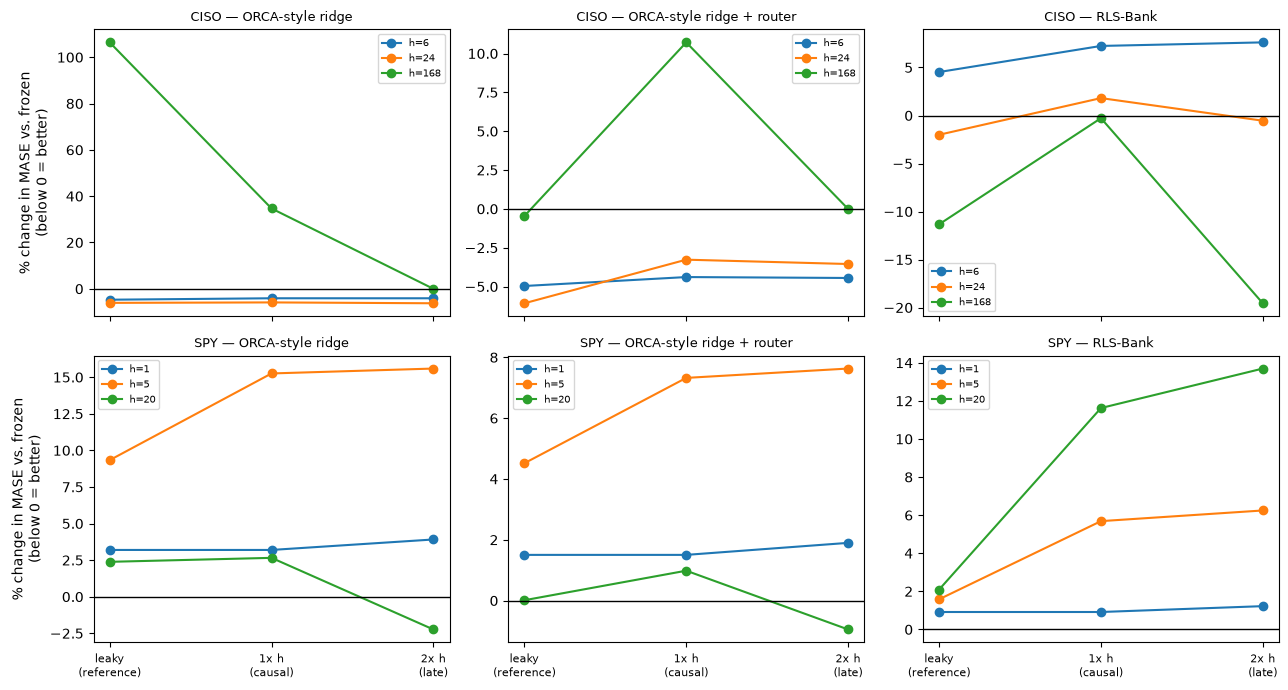

In [9]:
delay_models = list(fitted["CISO"][2])
fig, axes = plt.subplots(len(SERIES), len(delay_models), figsize=(13, 7), sharex=True)
for row, (name, cfg) in enumerate(SERIES.items()):
    for col, model in enumerate(delay_models):
        ax = axes[row, col]
        d = delay_table[(delay_table["series"] == name) & (delay_table["model"] == model)]
        for h, g in d.groupby("horizon"):
            g = g.set_index("delay").loc[[str(x) for x in DELAYS]]
            ax.plot(range(len(DELAYS)), g["pct_change_vs_frozen"], marker="o", label=f"h={h}")
        ax.axhline(0, color="black", linewidth=1)
        ax.set_xticks(range(len(DELAYS)))
        ax.set_xticklabels(["leaky\n(reference)", "1x h\n(causal)", "2x h\n(late)"], fontsize=8)
        ax.set_title(f"{name} — {model}", fontsize=9)
        if col == 0:
            ax.set_ylabel("% change in MASE vs. frozen\n(below 0 = better)")
        ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/figures/delay_axis{SUFFIX}.png", dpi=150)
plt.show()

## Cost

Per-origin wall time, Chronos-2 included. The corrector's share is the difference from the
frozen row.

In [10]:
cost = summary.groupby(["series", "model"])["mean_elapsed_seconds"].first().unstack(0)
frozen_cost = cost.loc[FROZEN]
pd.DataFrame({f"{s} total (s)": cost[s] for s in cost.columns} |
             {f"{s} corrector only (ms)": 1_000 * (cost[s] - frozen_cost[s]) for s in cost.columns}).round(4)

,CISO total (s),SPY total (s),CISO corrector only (ms),SPY corrector only (ms)
model,,,,
Chronos-2 (frozen),0.1035,0.0851,0.0000,0.0000
Naive,NaN,0.0000,NaN,-85.1322
ORCA-style ridge,0.1044,0.0854,0.8911,0.2241
ORCA-style ridge + router,0.1043,0.0854,0.8428,0.2122
RLS-Bank,0.1040,0.0855,0.4758,0.3862
Residual memory (online),0.1040,0.0855,0.5006,0.3381
Seasonal naive,0.0001,NaN,-103.4542,NaN


## Reading the results

- Start with the significance table, not the MASE bars. A corrector that's a few percent
  "better" with an interval straddling zero hasn't earned anything yet — at this sample size
  that's indistinguishable from noise.
- Compare against the predictions written down at the top: something on CISO, nothing on
  SPY. If CISO also shows nothing, Post 03's explanation (Chronos-2 already has the shape)
  is the obvious first suspect, not a bug.
- **ORCA-style vs. RLS-Bank** is the comparison neither paper ran. If the four-feature,
  no-tuning bank keeps up with the adapter that sees the whole context window, the adapter's
  extra capacity isn't buying anything on this series.
- **Router on vs. off:** ORCA's ablation calls the router its most important part. Its job
  is to stop the adapter from hurting; on a series where the adapter rarely helps, it should
  mostly hand control back to the frozen model.
- **Leaky column:** the gap between "leaky" and "1× h" is how much an evaluation that
  ignores label delay would have overstated each corrector. It's the reason the leaky
  numbers are never the headline.
- The validation-selected settings (printed above) are worth a glance: a residual-memory
  scale of 0, or a ridge strength at the top of the grid, means validation already found
  little to correct before test was touched.
- Set `SMALL_SCALE = False` and rerun for the full-scale numbers used in the post.